# DSPy + LangGraph: Client Brief → Design Brief → Concept Image

**Pipeline:** A client packaging brief enters. Four AI agents run in sequence:
1. **Trend Analyst** — market trends, consumer insights, competitor landscape
2. **Design Strategist** — color, typography, material, structural directions
3. **Brief Compiler** — assembles a client-ready design brief
4. **Visual Draft** — generates a first packaging concept image from the brief

**Outputs:** Brief printed in notebook · JSON file · PDF file

*PoC runs 100% locally via Ollama (llama3.2:3b). Production maps each agent to its optimal model.*

In [1]:
# Installs DSPy, LangGraph, Ollama client, fpdf2 (PDF export)
!pip install -q dspy langgraph langchain langchain-ollama langchain-core fpdf2
print("✅ Packages ready")


[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


✅ Packages ready


In [2]:
# Starts Ollama local LLM server and pulls llama3.2:3b (used by all agents in PoC)
import subprocess, time

!curl -fsSL https://ollama.com/install.sh | sh 2>/dev/null

subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(3)

!ollama pull llama3.2:3b

print()
print("✅ Ollama ready — llama3.2:3b loaded")
print()
print("   Agent            PoC model       Production model")
print("   Supervisor       llama3.2:3b     Claude Sonnet 4.5")
print("   Trend Analyst    llama3.2:3b     Manus / Perplexity")
print("   Design Strat.    llama3.2:3b     Gemini 2.5 Pro")
print("   Brief Compiler   llama3.2:3b     Claude Sonnet 4.5")
print("   Visual Draft     llama3.2:3b     DALL-E 3 / Flux")

2026/02/23 07:22:12 WARN MLX dynamic library not available error="failed to load MLX dynamic library (searched: [/opt/homebrew/Cellar/ollama/0.16.2/bin /Users/nihanbayrak/Desktop/build/lib/ollama])"
]11;?\

pulling manifest ⠋ 

pulling manifest ⠙ 

pulling manifest ⠹ 

pulling manifest ⠸ 

pulling manifest ⠼ 

pulling manifest ⠴ 

pulling manifest 
pulling dde5aa3fc5ff: 100% ▕██████████████████▏ 2.0 GB                         
pulling 966de95ca8a6: 100% ▕██████████████████▏ 1.4 KB                         
pulling fcc5a6bec9da: 100% ▕██████████████████▏ 7.7 KB                         
pulling a70ff7e570d9: 100% ▕██████████████████▏ 6.0 KB                         
pulling 56bb8bd477a5: 100% ▕██████████████████▏   96 B                         
pulling 34bb5ab01051: 100% ▕██████████████████▏  561 B                         
verifying sha256 digest 
writing manifest 
success 



✅ Ollama ready — llama3.2:3b loaded

   Agent            PoC model       Production model
   Supervisor       llama3.2:3b     Claude Sonnet 4.5
   Trend Analyst    llama3.2:3b     Manus / Perplexity
   Design Strat.    llama3.2:3b     Gemini 2.5 Pro
   Brief Compiler   llama3.2:3b     Claude Sonnet 4.5
   Visual Draft     llama3.2:3b     DALL-E 3 / Flux


In [3]:
# Configures DSPy to use the local Ollama instance as the LLM backend
import dspy

ollama_lm = dspy.LM(
    model="ollama_chat/llama3.2:3b",
    api_base="http://localhost:11434",
    temperature=0.3,
    max_tokens=1024
)
dspy.configure(lm=ollama_lm)
print("✅ DSPy configured with Ollama")

✅ DSPy configured with Ollama


In [4]:
# Defines input/output contracts (Signatures) for all four agents
import dspy

class TrendAnalysis(dspy.Signature):
    """Analyze current FMCG packaging trends for a specific product category and market.
    Focus on consumer behavior, sustainability, material innovations, and competitor strategies in Europe."""
    product_category: str = dspy.InputField(desc="Product category e.g. 'premium chocolate', 'organic dairy'")
    target_market: str    = dspy.InputField(desc="Target market e.g. 'German retail', 'Swiss premium'")
    client_context: str   = dspy.InputField(desc="Client name and project context")
    market_trends: str          = dspy.OutputField(desc="3-5 key market trends affecting packaging design")
    consumer_insights: str      = dspy.OutputField(desc="Key consumer behavior shifts relevant to packaging")
    competitor_landscape: str   = dspy.OutputField(desc="How top 3 competitors approach their packaging")
    sustainability_factors: str = dspy.OutputField(desc="Sustainability trends and EU regulatory considerations (PPWR)")


class DesignStrategy(dspy.Signature):
    """Translate market trends into actionable packaging design directions
    covering color, typography, materials, and structural design."""
    market_trends: str          = dspy.InputField(desc="Market trends from Trend Analyst")
    consumer_insights: str      = dspy.InputField(desc="Consumer behavior insights")
    sustainability_factors: str = dspy.InputField(desc="Sustainability context")
    client_context: str         = dspy.InputField(desc="Client name and requirements")
    color_direction: str         = dspy.OutputField(desc="Color palette with hex codes and rationale")
    typography_direction: str    = dspy.OutputField(desc="Font style recommendations")
    material_recommendation: str = dspy.OutputField(desc="Material suggestions with sustainability score")
    structural_concept: str      = dspy.OutputField(desc="Packaging structure recommendations")
    design_rationale: str        = dspy.OutputField(desc="Strategic rationale connecting design to insights")


class DesignBrief(dspy.Signature):
    """Compile all research and strategy into a professional, client-ready packaging design brief."""
    client_context: str          = dspy.InputField(desc="Original client brief")
    market_trends: str           = dspy.InputField(desc="Trend analysis output")
    consumer_insights: str       = dspy.InputField(desc="Consumer insights")
    competitor_landscape: str    = dspy.InputField(desc="Competitor analysis")
    color_direction: str         = dspy.InputField(desc="Color palette recommendations")
    typography_direction: str    = dspy.InputField(desc="Typography recommendations")
    material_recommendation: str = dspy.InputField(desc="Material suggestions")
    structural_concept: str      = dspy.InputField(desc="Structural design concepts")
    design_rationale: str        = dspy.InputField(desc="Strategic rationale")
    executive_summary: str = dspy.OutputField(desc="2-3 sentence exec summary")
    full_brief: str        = dspy.OutputField(desc="Complete design brief for presentation")
    next_steps: str        = dspy.OutputField(desc="Recommended next steps with timeline")


class VisualDraftPrompt(dspy.Signature):
    """Generate a detailed image generation prompt for packaging design based on the brief.
    Optimize for Stable Diffusion / DALL-E."""
    executive_summary: str       = dspy.InputField(desc="Brief executive summary")
    color_direction: str         = dspy.InputField(desc="Color palette with hex codes")
    typography_direction: str    = dspy.InputField(desc="Typography style")
    material_recommendation: str = dspy.InputField(desc="Packaging material")
    structural_concept: str      = dspy.InputField(desc="Packaging structure/form")
    client_context: str          = dspy.InputField(desc="Client and product context")
    image_prompt: str    = dspy.OutputField(desc="Detailed image prompt (100-200 words) for text-to-image models. Include: product type, packaging shape, colors, materials, lighting, camera angle, style keywords")
    negative_prompt: str = dspy.OutputField(desc="Negative prompt: what to exclude (blurry, text, watermark, low quality)")

print("✅ 4 signatures defined: TrendAnalysis · DesignStrategy · DesignBrief · VisualDraftPrompt")

✅ 4 signatures defined: TrendAnalysis · DesignStrategy · DesignBrief · VisualDraftPrompt


In [5]:
# Wraps each Signature in a ChainOfThought module and instantiates all four agents
import dspy

class TrendAnalystAgent(dspy.Module):
    def __init__(self):
        super().__init__()
        self.analyze = dspy.ChainOfThought(TrendAnalysis)
    def forward(self, product_category, target_market, client_context):
        return self.analyze(product_category=product_category, target_market=target_market, client_context=client_context)

class DesignStrategistAgent(dspy.Module):
    def __init__(self):
        super().__init__()
        self.strategize = dspy.ChainOfThought(DesignStrategy)
    def forward(self, market_trends, consumer_insights, sustainability_factors, client_context):
        return self.strategize(market_trends=market_trends, consumer_insights=consumer_insights,
                               sustainability_factors=sustainability_factors, client_context=client_context)

class BriefCompilerAgent(dspy.Module):
    def __init__(self):
        super().__init__()
        self.compile_brief = dspy.ChainOfThought(DesignBrief)
    def forward(self, **kwargs):
        return self.compile_brief(**kwargs)

class VisualDraftAgent(dspy.Module):
    def __init__(self):
        super().__init__()
        self.generate_prompt = dspy.ChainOfThought(VisualDraftPrompt)
    def forward(self, **kwargs):
        return self.generate_prompt(**kwargs)

trend_agent  = TrendAnalystAgent()
design_agent = DesignStrategistAgent()
brief_agent  = BriefCompilerAgent()
visual_agent = VisualDraftAgent()

print("✅ Agents ready: TrendAnalyst · DesignStrategist · BriefCompiler · VisualDraft")

✅ Agents ready: TrendAnalyst · DesignStrategist · BriefCompiler · VisualDraft


In [6]:
# Defines the shared state TypedDict that carries all data through the LangGraph workflow
from typing import TypedDict, Annotated
from langchain_core.messages import HumanMessage, BaseMessage
import operator

class TrendToDesignBriefState(TypedDict):
    messages: Annotated[list[BaseMessage], operator.add]
    client_name: str
    product_category: str
    target_market: str
    client_context: str
    market_trends: str
    consumer_insights: str
    competitor_landscape: str
    sustainability_factors: str
    color_direction: str
    typography_direction: str
    material_recommendation: str
    structural_concept: str
    design_rationale: str
    executive_summary: str
    full_brief: str
    next_steps: str
    image_prompt: str
    negative_prompt: str
    generated_image_path: str
    current_agent: str
    workflow_status: str
    error_log: str

print("✅ State schema defined (22 fields)")

✅ State schema defined (22 fields)


In [7]:
# Generates a packaging concept card locally using matplotlib (no API, no internet required)
import re, textwrap
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

def generate_image_from_prompt(prompt: str, negative_prompt: str = "", extra: dict = None) -> str:
    output_path = "packaging_concept_draft.png"
    extra = extra or {}

    hex_colors = re.findall(r"#[0-9A-Fa-f]{6}", prompt)
    bg_color  = hex_colors[0] if len(hex_colors) > 0 else "#C8A951"
    acc_color = hex_colors[1] if len(hex_colors) > 1 else "#2C2C2C"

    client  = extra.get("client_name", "Brand")
    product = extra.get("product_category", "")

    fig, ax = plt.subplots(figsize=(8, 8))
    fig.patch.set_facecolor("#F5F0E8")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    ax.add_patch(FancyBboxPatch((0.05, 0.05), 0.90, 0.90,
        boxstyle="round,pad=0.02", facecolor=bg_color,
        edgecolor=acc_color, linewidth=3, transform=ax.transAxes, zorder=1))

    ax.add_patch(FancyBboxPatch((0.10, 0.12), 0.80, 0.52,
        boxstyle="round,pad=0.01", facecolor="white", alpha=0.12,
        edgecolor="white", linewidth=0, transform=ax.transAxes, zorder=2))

    ax.text(0.5, 0.84, client.upper(), ha="center", va="center",
            fontsize=34, fontweight="bold", color="white",
            transform=ax.transAxes, fontfamily="serif", zorder=3)

    ax.text(0.5, 0.73, textwrap.fill(product, 32), ha="center", va="center",
            fontsize=12, color="white", alpha=0.88,
            transform=ax.transAxes, style="italic", zorder=3)

    ax.plot([0.15, 0.85], [0.66, 0.66], color="white", alpha=0.45,
            linewidth=1, transform=ax.transAxes, zorder=3)

    swatch_y, n = 0.57, min(len(hex_colors), 5)
    for idx in range(n):
        x = 0.5 - (n - 1) * 0.05 + idx * 0.10
        ax.add_patch(plt.Circle((x, swatch_y), 0.034, color=hex_colors[idx],
                                transform=ax.transAxes, zorder=4))

    excerpt = textwrap.fill(prompt[:220], 58)
    ax.text(0.5, 0.40, excerpt, ha="center", va="center",
            fontsize=7.5, color="white", alpha=0.82,
            transform=ax.transAxes, zorder=3)

    ax.text(0.5, 0.16, "FIRST CONCEPT DRAFT", ha="center", va="center",
            fontsize=9, color="white", alpha=0.65,
            transform=ax.transAxes, zorder=3)
    ax.text(0.5, 0.10, "Generated by DSPy + LangGraph Pipeline",
            ha="center", va="center", fontsize=7, color="white", alpha=0.45,
            transform=ax.transAxes, zorder=3)

    plt.tight_layout(pad=0)
    plt.savefig(output_path, dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
    plt.close()
    print(f"   Concept card saved: {output_path}")
    return output_path

print("✅ Local image generator ready (matplotlib, no API required)")

✅ Local image generator ready (matplotlib, no API required)


In [8]:
# Defines all five LangGraph nodes: one per agent plus the supervisor router
from langchain_core.messages import HumanMessage

def trend_analysis_node(state: TrendToDesignBriefState) -> dict:
    print("🔍 Trend Analyst running...")
    try:
        r = trend_agent(product_category=state["product_category"],
                        target_market=state["target_market"],
                        client_context=state["client_context"])
        print("   ✅ Done")
        return {
            "market_trends": r.market_trends, "consumer_insights": r.consumer_insights,
            "competitor_landscape": r.competitor_landscape, "sustainability_factors": r.sustainability_factors,
            "current_agent": "trend_analyst_done",
            "messages": [HumanMessage(content=f"[Trend Analyst] Done for {state['client_name']}")]
        }
    except Exception as e:
        return {"current_agent": "trend_analyst_error", "error_log": str(e),
                "messages": [HumanMessage(content=f"[Trend Analyst] ERROR: {e}")]}

def design_strategy_node(state: TrendToDesignBriefState) -> dict:
    print("🎨 Design Strategist running...")
    try:
        r = design_agent(market_trends=state.get("market_trends", ""),
                         consumer_insights=state.get("consumer_insights", ""),
                         sustainability_factors=state.get("sustainability_factors", ""),
                         client_context=state["client_context"])
        print("   ✅ Done")
        return {
            "color_direction": r.color_direction, "typography_direction": r.typography_direction,
            "material_recommendation": r.material_recommendation, "structural_concept": r.structural_concept,
            "design_rationale": r.design_rationale, "current_agent": "design_strategist_done",
            "messages": [HumanMessage(content="[Design Strategist] Done")]
        }
    except Exception as e:
        return {"current_agent": "design_strategist_error", "error_log": str(e),
                "messages": [HumanMessage(content=f"[Design Strategist] ERROR: {e}")]}

def brief_compilation_node(state: TrendToDesignBriefState) -> dict:
    print("📋 Brief Compiler running...")
    try:
        r = brief_agent(
            client_context=state["client_context"],
            market_trends=state.get("market_trends", ""),
            consumer_insights=state.get("consumer_insights", ""),
            competitor_landscape=state.get("competitor_landscape", ""),
            color_direction=state.get("color_direction", ""),
            typography_direction=state.get("typography_direction", ""),
            material_recommendation=state.get("material_recommendation", ""),
            structural_concept=state.get("structural_concept", ""),
            design_rationale=state.get("design_rationale", "")
        )
        print("   ✅ Done")
        return {
            "executive_summary": r.executive_summary, "full_brief": r.full_brief, "next_steps": r.next_steps,
            "current_agent": "brief_compiler_done", "workflow_status": "COMPLETE",
            "messages": [HumanMessage(content="[Brief Compiler] Brief ready")]
        }
    except Exception as e:
        return {"current_agent": "brief_compiler_error", "error_log": str(e),
                "messages": [HumanMessage(content=f"[Brief Compiler] ERROR: {e}")]}

def visual_draft_node(state: TrendToDesignBriefState) -> dict:
    print("🖼️  Visual Draft running...")
    try:
        pr = visual_agent(
            executive_summary=state.get("executive_summary", ""),
            color_direction=state.get("color_direction", ""),
            typography_direction=state.get("typography_direction", ""),
            material_recommendation=state.get("material_recommendation", ""),
            structural_concept=state.get("structural_concept", ""),
            client_context=state["client_context"]
        )
        print(f"   Prompt: {pr.image_prompt[:80]}...")
        generated_path = generate_image_from_prompt(pr.image_prompt, pr.negative_prompt, extra=state)
        print("   ✅ Done")
        return {
            "image_prompt": pr.image_prompt, "negative_prompt": pr.negative_prompt,
            "generated_image_path": generated_path, "current_agent": "visual_draft_done",
            "messages": [HumanMessage(content="[Visual Draft] Concept image generated")]
        }
    except Exception as e:
        return {"current_agent": "visual_draft_error", "error_log": str(e),
                "image_prompt": "", "negative_prompt": "", "generated_image_path": "",
                "messages": [HumanMessage(content=f"[Visual Draft] ERROR: {e}")]}

def supervisor_node(state: TrendToDesignBriefState) -> dict:
    routing = {
        "start":                  "trend_analyst",
        "trend_analyst_done":     "design_strategist",
        "design_strategist_done": "brief_compiler",
        "brief_compiler_done":    "visual_draft",
        "visual_draft_done":      "FINISH",
    }
    current = state.get("current_agent", "start")
    next_agent = routing.get(current, "FINISH")
    if "error" in current:
        next_agent = "FINISH"
    return {"current_agent": next_agent}

print("✅ All 5 nodes defined")

✅ All 5 nodes defined


✅ Graph compiled: START → Trend → Design → Brief → Visual Draft → END


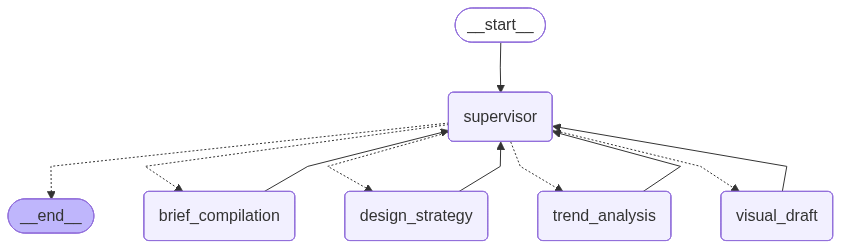

In [9]:
# Assembles the LangGraph StateGraph: supervisor routes between the four agent nodes in sequence
from langgraph.graph import StateGraph, END, START

def route_from_supervisor(state: TrendToDesignBriefState) -> str:
    routing = {
        "trend_analyst":     "trend_analysis",
        "design_strategist": "design_strategy",
        "brief_compiler":    "brief_compilation",
        "visual_draft":      "visual_draft",
    }
    return routing.get(state.get("current_agent", ""), END)

workflow = StateGraph(TrendToDesignBriefState)
workflow.add_node("supervisor",        supervisor_node)
workflow.add_node("trend_analysis",    trend_analysis_node)
workflow.add_node("design_strategy",   design_strategy_node)
workflow.add_node("brief_compilation", brief_compilation_node)
workflow.add_node("visual_draft",      visual_draft_node)

workflow.add_edge(START,               "supervisor")
workflow.add_edge("trend_analysis",    "supervisor")
workflow.add_edge("design_strategy",   "supervisor")
workflow.add_edge("brief_compilation", "supervisor")
workflow.add_edge("visual_draft",      "supervisor")

workflow.add_conditional_edges("supervisor", route_from_supervisor, {
    "trend_analysis":    "trend_analysis",
    "design_strategy":   "design_strategy",
    "brief_compilation": "brief_compilation",
    "visual_draft":      "visual_draft",
    END: END
})

app = workflow.compile()
print("✅ Graph compiled: START → Trend → Design → Brief → Visual Draft → END")

try:
    from IPython.display import Image, display
    display(Image(app.get_graph().draw_mermaid_png()))
except:
    pass

In [10]:
# Runs the full pipeline end-to-end with a Lindt Christmas 2025 client brief
from langchain_core.messages import HumanMessage

CLIENT_BRIEF = {
    "client_name":      "Lindt",
    "product_category": "premium chocolate gift boxes",
    "target_market":    "German retail market",
    "client_context": (
        "CLIENT: Lindt & Spruengli\n"
        "PROJECT: Christmas Collection 2025 — German Market\n"
        "BRIEF: Redesign premium chocolate gift box packaging.\n"
        "REQUIREMENTS:\n"
        "- Luxurious and gift-worthy\n"
        "- Address sustainability (eco-conscious consumers)\n"
        "- Stand out vs Ferrero, Milka, Ritter Sport\n"
        "- Appeal to 30-55 year old gift buyers\n"
        "- Maintain Lindt gold/premium brand identity\n"
        "CONSTRAINTS:\n"
        "- EU PPWR compliance\n"
        "- Mid-premium budget\n"
        "- Concepts by March, production-ready by July"
    ),
}

initial_state = {
    "messages": [HumanMessage(content=f"New project: {CLIENT_BRIEF['client_name']}")],
    **CLIENT_BRIEF,
    "market_trends": "", "consumer_insights": "", "competitor_landscape": "",
    "sustainability_factors": "", "color_direction": "", "typography_direction": "",
    "material_recommendation": "", "structural_concept": "", "design_rationale": "",
    "executive_summary": "", "full_brief": "", "next_steps": "",
    "image_prompt": "", "negative_prompt": "", "generated_image_path": "",
    "current_agent": "start", "workflow_status": "RUNNING", "error_log": ""
}

print("=" * 60)
print(f"PIPELINE START — {CLIENT_BRIEF['client_name']}")
print("=" * 60)

# stream_mode="values" yields the full cumulative state after each node
final_state = None
for state_snapshot in app.stream(initial_state, {"recursion_limit": 20}, stream_mode="values"):
    agent = state_snapshot.get("current_agent", "")
    if agent:
        print(f"  ✓ {agent}")
    final_state = state_snapshot

print("=" * 60)
print("PIPELINE COMPLETE")
print("=" * 60)

PIPELINE START — Lindt
  ✓ start
  ✓ trend_analyst
🔍 Trend Analyst running...
   ✅ Done
  ✓ trend_analyst_done
  ✓ design_strategist
🎨 Design Strategist running...
   ✅ Done
  ✓ design_strategist_done
  ✓ brief_compiler
📋 Brief Compiler running...
   ✅ Done
  ✓ brief_compiler_done
  ✓ visual_draft
🖼️  Visual Draft running...
   Prompt: A high-quality image of a luxurious, eco-friendly gift box for Lindt's Christmas...


   Concept card saved: packaging_concept_draft.png
   ✅ Done
  ✓ visual_draft_done
  ✓ FINISH
PIPELINE COMPLETE


EXECUTIVE SUMMARY
--------------------------------------------------
Lindt & Spruengli's Christmas Collection 2025 — German Market requires a premium chocolate gift box packaging that addresses sustainability, luxury, and modernity. Our design brief incorporates eco-friendly materials, luxurious typography, and a minimalist aesthetic to create a unique and appealing package that meets EU PPWR compliance and maintains Lindt's gold brand identity.

FULL DESIGN BRIEF
--------------------------------------------------
**Design Brief: Lindt & Spruengli Christmas Collection 2025 — German Market**

**Project Overview**
Redesign premium chocolate gift box packaging for Lindt & Spruengli's Christmas Collection 2025, targeting the German market. The new design should address sustainability, luxury, and modernity while maintaining Lindt's gold brand identity.

**Key Requirements**

* Luxurious and gift-worthy
* Address sustainability (eco-conscious consumers)
* Stand out vs Ferrero, Milka, Ritter

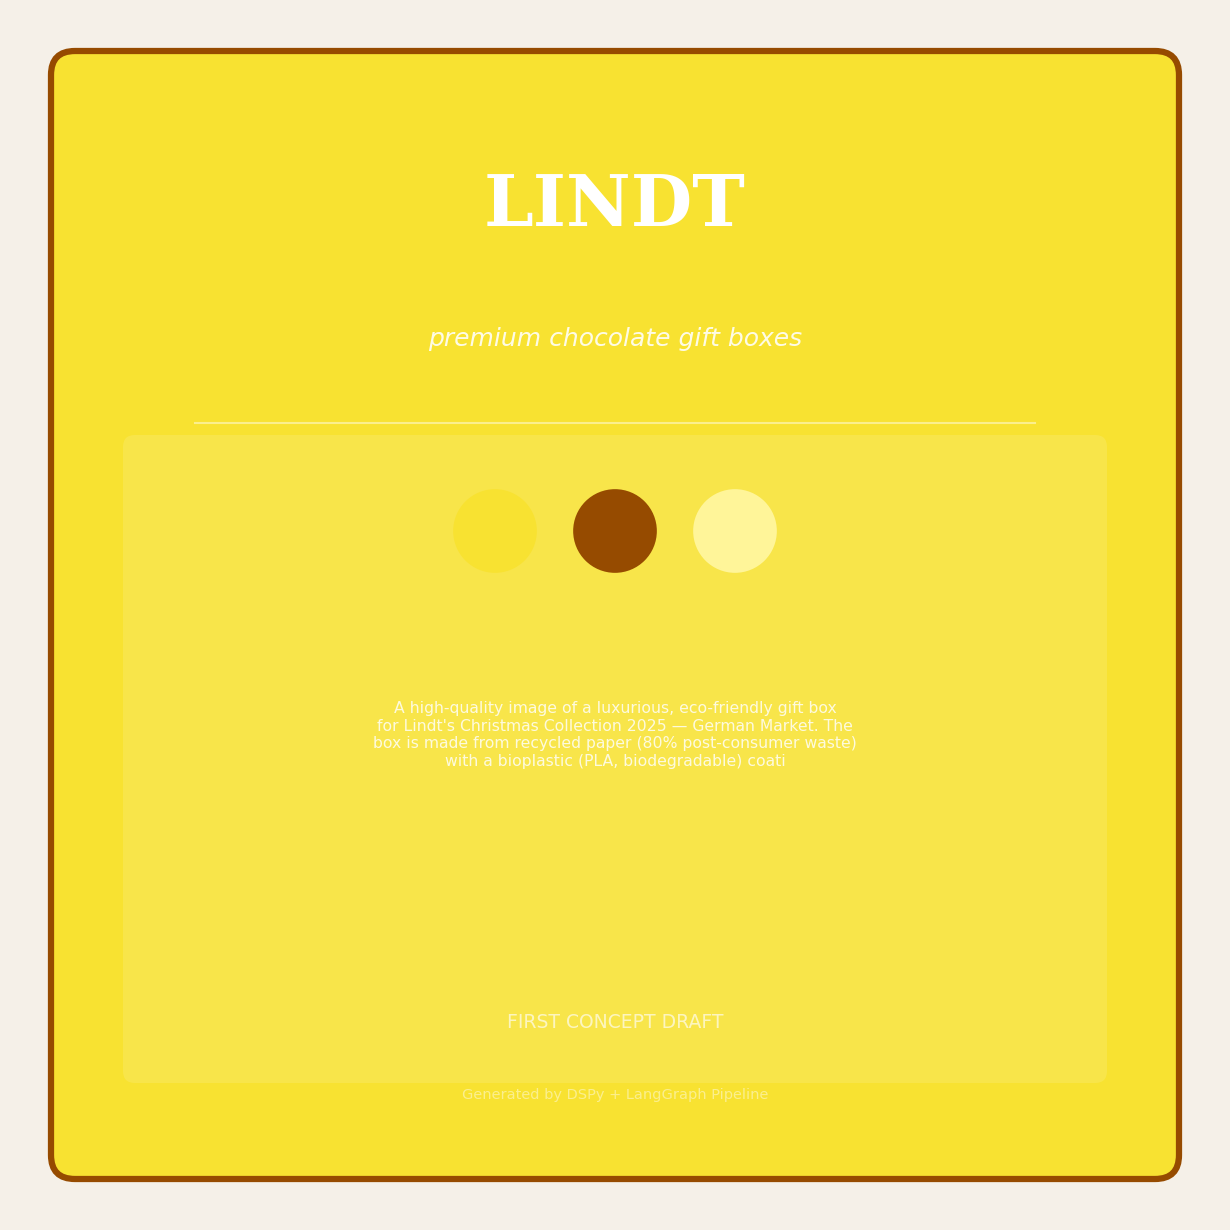


IMAGE PROMPT:
A high-quality image of a luxurious, eco-friendly gift box for Lindt's Christmas Collection 2025 — German Market. The box is made from recycled paper (80% post-consumer waste) with a bioplastic (PLA, biodegradable) coating. The main color is Warm Gold (#F8E231), with secondary colors Earthy Brown (#964B00) and Rich Cream (#FFF599). The font style is Playfair Display, with 36pt for the main text and 24pt for secondary text. The packaging structure features a rectangular shape with rounded corners and a minimalist window to showcase the chocolate. The lighting is soft and warm, with a camera angle that highlights the luxurious design. Style keywords: luxury, sustainability, modernity, eco-friendly, premium, gift box.


In [11]:
# Prints the executive summary, full brief, next steps, and displays the generated concept image
last = final_state or {}

print("EXECUTIVE SUMMARY")
print("-" * 50)
print(last.get("executive_summary", "N/A"))
print()
print("FULL DESIGN BRIEF")
print("-" * 50)
print(last.get("full_brief", "N/A"))
print()
print("NEXT STEPS")
print("-" * 50)
print(last.get("next_steps", "N/A"))

img_path = last.get("generated_image_path", "")
if img_path:
    print()
    print("PACKAGING CONCEPT IMAGE")
    print("-" * 50)
    try:
        from IPython.display import Image as IPImage, display
        if img_path.endswith(".png"):
            display(IPImage(filename=img_path))
        else:
            print(f"Prompt file: {img_path}")
    except Exception as e:
        print(f"Image at: {img_path}")

if last.get("image_prompt"):
    print()
    print("IMAGE PROMPT:")
    print(last.get("image_prompt", ""))

In [12]:
# Exports the complete pipeline output to JSON and a formatted PDF design brief (with concept image embedded)
import json, os, datetime
from fpdf import FPDF

last       = final_state or {}
client     = last.get("client_name", "client").replace(" ", "_")
timestamp  = datetime.datetime.now().strftime("%Y%m%d_%H%M")
json_path  = f"{client}_design_brief_{timestamp}.json"
pdf_path   = f"{client}_design_brief_{timestamp}.pdf"

def sanitize(text):
    """Replace non-latin-1 characters so fpdf built-in fonts can render them."""
    replacements = {
        "\u2014": "-", "\u2013": "-", "\u2018": "'", "\u2019": "'",
        "\u201c": '"', "\u201d": '"', "\u2026": "...", "\u2022": "-",
        "\u20ac": "EUR", "\u00a0": " ",
    }
    for char, rep in replacements.items():
        text = text.replace(char, rep)
    return text.encode("latin-1", errors="replace").decode("latin-1")

# ── JSON ─────────────────────────────────────────────────────────────────────
fields = [
    "client_name", "product_category", "target_market", "client_context",
    "market_trends", "consumer_insights", "competitor_landscape", "sustainability_factors",
    "color_direction", "typography_direction", "material_recommendation",
    "structural_concept", "design_rationale",
    "executive_summary", "full_brief", "next_steps",
    "image_prompt", "negative_prompt", "generated_image_path", "workflow_status"
]
output_json = {k: last.get(k, "") for k in fields}
output_json["exported_at"] = timestamp

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(output_json, f, indent=2, ensure_ascii=False)
print(f"✅ JSON -> {json_path}")

# ── PDF ──────────────────────────────────────────────────────────────────────
class DesignBriefPDF(FPDF):
    def header(self):
        self.set_font("Helvetica", "B", 9)
        self.set_text_color(150, 150, 150)
        self.cell(0, 8, "DESIGN BRIEF - CONFIDENTIAL", align="R")
        self.ln(4)
        self.set_draw_color(210, 210, 210)
        self.line(15, self.get_y(), 195, self.get_y())
        self.ln(4)

    def footer(self):
        self.set_y(-15)
        self.set_font("Helvetica", "I", 8)
        self.set_text_color(150, 150, 150)
        self.cell(0, 10, f"Page {self.page_no()} - {timestamp}", align="C")

    def section(self, title):
        self.ln(5)
        self.set_font("Helvetica", "B", 11)
        self.set_text_color(30, 30, 30)
        self.set_fill_color(245, 245, 245)
        self.cell(0, 7, sanitize(title), fill=True, ln=True)
        self.ln(1)

    def body(self, text):
        self.set_font("Helvetica", "", 10)
        self.set_text_color(55, 55, 55)
        self.multi_cell(0, 6, sanitize(text or "-"))
        self.ln(1)

pdf = DesignBriefPDF()
pdf.set_margins(15, 20, 15)
pdf.set_auto_page_break(auto=True, margin=20)
pdf.add_page()

# Title
pdf.set_font("Helvetica", "B", 20)
pdf.set_text_color(20, 20, 20)
pdf.cell(0, 11, sanitize(f"{last.get('client_name', 'Client')} - Packaging Design Brief"), ln=True)
pdf.set_font("Helvetica", "", 11)
pdf.set_text_color(100, 100, 100)
pdf.cell(0, 6, sanitize(f"{last.get('product_category', '')}  |  {last.get('target_market', '')}"), ln=True)
pdf.cell(0, 6, f"Generated: {datetime.datetime.now().strftime('%B %d, %Y')}", ln=True)
pdf.ln(3)
pdf.set_draw_color(180, 180, 180)
pdf.line(15, pdf.get_y(), 195, pdf.get_y())

pdf.section("Executive Summary");    pdf.body(last.get("executive_summary", ""))
pdf.section("Client Brief");         pdf.body(last.get("client_context", ""))
pdf.section("Market Trends");        pdf.body(last.get("market_trends", ""))
pdf.section("Consumer Insights");    pdf.body(last.get("consumer_insights", ""))
pdf.section("Competitor Landscape"); pdf.body(last.get("competitor_landscape", ""))
pdf.section("Sustainability");       pdf.body(last.get("sustainability_factors", ""))
pdf.section("Color Direction");      pdf.body(last.get("color_direction", ""))
pdf.section("Typography");           pdf.body(last.get("typography_direction", ""))
pdf.section("Materials");            pdf.body(last.get("material_recommendation", ""))
pdf.section("Structural Concept");   pdf.body(last.get("structural_concept", ""))
pdf.section("Design Rationale");     pdf.body(last.get("design_rationale", ""))
pdf.section("Full Design Brief");    pdf.body(last.get("full_brief", ""))
pdf.section("Next Steps");           pdf.body(last.get("next_steps", ""))

img = last.get("generated_image_path", "")
if img and img.endswith(".png") and os.path.exists(img):
    pdf.add_page()
    pdf.section("Packaging Concept - First Visual Draft")
    pdf.set_font("Helvetica", "I", 8)
    pdf.set_text_color(120, 120, 120)
    pdf.multi_cell(0, 5, sanitize(f"Prompt: {last.get('image_prompt', '')[:300]}"))
    pdf.ln(4)
    pdf.image(img, x=15, w=pdf.w - 30)
else:
    pdf.section("Visual Draft Prompt")
    pdf.body(last.get("image_prompt", "Image generation failed - paste prompt into Midjourney / DALL-E / ComfyUI"))

pdf.output(pdf_path)
print(f"✅ PDF  -> {pdf_path}")
print()
print(f"Files saved in: {os.path.abspath('.')}")

✅ JSON -> Lindt_design_brief_20260223_0722.json


✅ PDF  -> Lindt_design_brief_20260223_0722.pdf

Files saved in: /Users/nihanbayrak/Desktop


/var/folders/ww/nnlw1wm54035bgdzgc09ylkh0000gn/T/ipykernel_69634/947542683.py:77: DeprecationWarning: The parameter "ln" is deprecated since v2.5.2. Instead of ln=True use new_x=XPos.LMARGIN, new_y=YPos.NEXT.
  pdf.cell(0, 11, sanitize(f"{last.get('client_name', 'Client')} - Packaging Design Brief"), ln=True)
/var/folders/ww/nnlw1wm54035bgdzgc09ylkh0000gn/T/ipykernel_69634/947542683.py:80: DeprecationWarning: The parameter "ln" is deprecated since v2.5.2. Instead of ln=True use new_x=XPos.LMARGIN, new_y=YPos.NEXT.
  pdf.cell(0, 6, sanitize(f"{last.get('product_category', '')}  |  {last.get('target_market', '')}"), ln=True)
/var/folders/ww/nnlw1wm54035bgdzgc09ylkh0000gn/T/ipykernel_69634/947542683.py:81: DeprecationWarning: The parameter "ln" is deprecated since v2.5.2. Instead of ln=True use new_x=XPos.LMARGIN, new_y=YPos.NEXT.
  pdf.cell(0, 6, f"Generated: {datetime.datetime.now().strftime('%B %d, %Y')}", ln=True)
/var/folders/ww/nnlw1wm54035bgdzgc09ylkh0000gn/T/ipykernel_69634/947542